In [ ]:
# GPU Check Script
import torch
print(f" GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f" GPU Name: {torch.cuda.get_device_name(0)}")
    print(f" VRAM Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print(" NO GPU!")

 GPU Available: True
 GPU Name: NVIDIA GB10
 VRAM Total: 128.52 GB


/home/admin/miniconda3/envs/granite-docling-gpu/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.warn(


### Load Model

In [2]:
import torch
import torch.nn.functional as F
from tqdm import tqdm
import numpy as np
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

model_name = "OpenLLM-Ro/RoLlama2-7b-Base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float16, 
    device_map="auto",
    trust_remote_code=True
)

print(" Model loaded!")
print(f" VRAM used: {torch.cuda.memory_reserved() / 1e9:.2f} GB")



/home/admin/miniconda3/envs/granite-docling-gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading checkpoint shards: 100%|██████████| 3/3 [01:36<00:00, 32.16s/it]


 Model loaded!
 VRAM used: 14.81 GB


## Calibration Dataset

### Load Dataset

In [13]:
from datasets import load_dataset

print(f"\n Loading Wikipedia Romanian Dataset...")

dataset_ro = load_dataset(
    "wikimedia/wikipedia",
    "20231101.ro",
    split="train"
)

print(f" Dataset loaded!")
print(f"   Total articles: {len(dataset_ro):,}")

# Sample preview
sample = dataset_ro[0]
print(f"\n Sample article:")
print(f"   Title: {sample['title']}")
print(f"   Length: {len(sample['text'])} chars")
print(f"   Preview: {sample['text'][:200]}...")


 Loading Wikipedia Romanian Dataset...
 Dataset loaded!
   Total articles: 442,389

 Sample article:
   Title: Rocarta
   Length: 4155 chars
   Preview: Rocarta este o enciclopedie în format electronic care conține articole legate de România, Republica Moldova și români. Ediția din 2000 conține aproximativ 3.000 de articole și peste 3.300 de imagini. ...


In [ ]:
print(model.config)

### Prepare calibration data samples

In [14]:
from tqdm import tqdm
import random
import numpy as np

num_samples = 256
sequence_length = 2048
min_article_length = 1000

print(f"\n Preparing {num_samples} calibration samples (Romanian)...")

# Shuffle indices
indices = list(range(len(dataset_ro)))
random.shuffle(indices)

calibration_data_ro = []
skipped = 0

for idx in tqdm(indices, desc="Loading RO samples", total=num_samples):
    if len(calibration_data_ro) >= num_samples:
        break
    
    article = dataset_ro[idx]
    text = article.get("text", "")
    
    # Filter for minimum length
    if len(text) < min_article_length:
        skipped += 1
        continue
    
    # Tokenize
    try:
        tokens = tokenizer(
            text,
            max_length=sequence_length,
            truncation=True,
            padding=False,
            return_tensors="pt"
        )
        
        # Keep only if at least half of max_length
        if tokens['input_ids'].shape[1] >= 1024:
            calibration_data_ro.append(tokens)
        else:
            skipped += 1
        
        if len(calibration_data_ro) % 50 == 0:
            print(f"  - {len(calibration_data_ro)}/{num_samples}")
    except:
        skipped += 1
        continue

print(f"\n Romanian calibration ready: {len(calibration_data_ro)} samples (skipped {skipped})")

# Token statistics
lengths = [s['input_ids'].shape[1] for s in calibration_data_ro]
total_tokens = sum(lengths)

print(f"\n Token Statistics:")
print(f"   Mean:  {np.mean(lengths):.0f} tokens")
print(f"   Std:   {np.std(lengths):.0f}")
print(f"   Min:   {np.min(lengths)}")
print(f"   Max:   {np.max(lengths)}")
print(f"   Total: {total_tokens:,} tokens")  # ← IMPORTANT!

# Paper comparison
paper_total = 256 * 2048
print(f"\n Comparison with Paper:")
print(f"   Paper (Llama2): {paper_total:,} tokens (256 × 2048)")
print(f"   Yours (RoLlama): {total_tokens:,} tokens")
print(f"   Ratio: {total_tokens / paper_total:.2%}")

# Diversity check
unique_starts = set()
for sample in calibration_data_ro[:50]:
    text = tokenizer.decode(sample['input_ids'][0])
    unique_starts.add(text[:100])

diversity_ro = len(unique_starts) / 50 * 100
print(f"\n Diversity: {diversity_ro:.1f}%")

if diversity_ro < 70:
    print("    Low diversity!")
else:
    print("    Good diversity")

# Save calibration data
with open("calibration_data_ro_2048.txt", "w", encoding="utf-8") as f:
    for i, sample in enumerate(calibration_data_ro):
        text = tokenizer.decode(sample['input_ids'][0])
        f.write(f"=== Sample {i+1} ({sample['input_ids'].shape[1]} tokens) ===\n\n")
        f.write(text + "\n\n")

print(f"\n Calibration data saved to 'calibration_data_ro_2048.txt'")


 Preparing 256 calibration samples (Romanian)...


Loading RO samples: 483it [00:00, 1328.51it/s]                         

  - 50/256


Loading RO samples: 855it [00:00, 1535.72it/s]

  - 100/256
  - 100/256
  - 100/256
  - 150/256


Loading RO samples: 1485it [00:00, 1879.41it/s]

  - 200/256
  - 250/256


Loading RO samples: 1685it [00:00, 1700.43it/s]


  - 250/256
  - 250/256
  - 250/256

 Romanian calibration ready: 256 samples (skipped 1429)

 Token Statistics:
   Mean:  1740 tokens
   Std:   372
   Min:   1028
   Max:   2048
   Total: 445,534 tokens

 Comparison with Paper:
   Paper (Llama2): 524,288 tokens (256 × 2048)
   Yours (RoLlama): 445,534 tokens
   Ratio: 84.98%

 Diversity: 100.0%
    Good diversity

 Calibration data saved to 'calibration_data_ro_2048.txt'


### Calculate cosine similarity and importance scores

In [ ]:
import math
import inspect
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from tqdm import tqdm


# 1) Prepare calibration inputs 
@torch.no_grad()
def prepare_calibration_inputs_paper_style(model, calibration_data, num_samples=256):
    """
    Wraps layer0 with a Catcher that stores the hidden_states + kwargs fed to layer0,
    then raises to stop the forward. This matches the repo's strategy.

    Returns:
      inputs:  list[tensor] of hidden_states entering layer0, len = N
      outputs: list[None] placeholder, len = N
      kw_list: list[dict] kwargs that were passed to layer0, len = N
    """
    layers = model.model.layers
    device = next(model.parameters()).device

    cache_inputs = []
    cache_kwargs = []

    class Catcher(nn.Module):
        def __init__(self, module):
            super().__init__()
            self.module = module

        def forward(self, hidden_states, **kwargs):
            cache_inputs.append(hidden_states.detach())
            # we keep exactly what the model passes to the decoder layer
            # (attention_mask is typically the causal mask already)
            kept = {
                "attention_mask": kwargs.get("attention_mask", None),
                "position_ids": kwargs.get("position_ids", None),
                "cache_position": kwargs.get("cache_position", None),
                "position_embeddings": kwargs.get("position_embeddings", None),
                "past_key_values": kwargs.get("past_key_values", None),
                "use_cache": kwargs.get("use_cache", None),
            }
            cache_kwargs.append(kept)
            raise ValueError("Catcher stop")

    orig0 = layers[0]
    layers[0] = Catcher(orig0)

    n = 0
    for sample in calibration_data:
        if n >= num_samples:
            break
        batch = {k: v.to(device) for k, v in sample.items()}
        if "attention_mask" not in batch:
            batch["attention_mask"] = torch.ones_like(batch["input_ids"], device=device)

        try:
            _ = model(**batch, use_cache=False)
        except ValueError:
            n += 1
            continue

    layers[0] = orig0

    outputs = [None] * len(cache_inputs)
    return cache_inputs, outputs, cache_kwargs


# 2) Helpers: filter kwargs to match a layer's forward signature
def filter_kwargs_for_forward(fn, kwargs: dict) -> dict:
    """
    Keeps only kwargs accepted by fn (by name), plus **kwargs support.
    """
    sig = inspect.signature(fn)
    params = sig.parameters
    if any(p.kind == p.VAR_KEYWORD for p in params.values()):
        # forward accepts **kwargs -> safe to pass everything non-None
        return {k: v for k, v in kwargs.items() if v is not None}

    accepted = set(params.keys())
    return {k: v for k, v in kwargs.items() if (k in accepted and v is not None)}


# 3) layer-by-layer similarities
@torch.no_grad()
def get_layer_similarities_paper_style(
    model,
    calibration_data,
    num_samples=256,
    target_layer="attn",     # "attn" or "mlp"
    drop_norm=True,          # True => X is input before LN 
    token_subsample=None,    # e.g. 100 to mimic the 100-token sampling; None => all tokens
    seed=0,
):
    """
    Returns similarities: np.ndarray [num_layers]
    similarity_l = mean_cos( X, X + f(...) ) aggregated over samples (and tokens).
    """
    assert target_layer in ["attn", "mlp"]

    # disable cache 
    if hasattr(model, "config"):
        model.config.use_cache = False
    if hasattr(model, "model") and hasattr(model.model, "config"):
        model.model.config.use_cache = False

    layers = model.model.layers
    num_layers = len(layers)
    device = next(model.parameters()).device

    # Step A: capture inputs to layer0 and the kwargs that model passes to layers
    inputs, outputs, kw_list = prepare_calibration_inputs_paper_style(
        model, calibration_data, num_samples=num_samples
    )
    N = len(inputs)
    if N == 0:
        raise RuntimeError("No calibration samples captured. Check calibration_data format / batch_size=1.")

    rng = torch.Generator(device="cpu")
    rng.manual_seed(seed)

    similarities = torch.full((num_layers,), -math.inf, device="cpu")

    # Step B: iterate layers, run each layer over all samples, swap buffers
    for i in tqdm(range(num_layers), desc=f"Layer-by-layer similarities ({target_layer})"):
        layer = layers[i]

        if target_layer == "mlp":
            module_pre_norm = layer.post_attention_layernorm
            module = layer.mlp
        else:
            module_pre_norm = layer.input_layernorm
            module = layer.self_attn

        # running accumulators for this layer
        cos_sum = 0.0
        tok_cnt = 0

        # per-call temporary state (LN hook stores X, module hook consumes it)
        state = {"x": None}

        def pre_norm_hook(mod, inp, out):
            # inp[0] is residual BEFORE LN, out is AFTER LN
            x = inp[0] if drop_norm else out
            state["x"] = x.detach()

        def module_hook(mod, inp, out):
            x = state["x"]
            if x is None:
                return

            out0 = out[0] if isinstance(out, tuple) else out
            y = x + out0.detach()

            x_f = x.reshape(-1, x.shape[-1]).float().cpu()
            y_f = y.reshape(-1, y.shape[-1]).float().cpu()

            if token_subsample is not None and x_f.shape[0] > token_subsample:
                # sample token_subsample indices without replacement
                idx = torch.randperm(x_f.shape[0], generator=rng)[:token_subsample]
                x_f = x_f[idx]
                y_f = y_f[idx]

            cos = F.cosine_similarity(x_f, y_f, dim=-1)  # [T] on CPU float32
            nonlocal cos_sum, tok_cnt
            cos_sum += float(cos.sum().item())
            tok_cnt += int(cos.numel())

            state["x"] = None  # consume

        h1 = module_pre_norm.register_forward_hook(pre_norm_hook)
        h2 = module.register_forward_hook(module_hook)

        # run this decoder layer on each captured sample
        for j in range(N):
            kwargs = dict(kw_list[j])  # shallow copy
            # ensure cache off
            kwargs["use_cache"] = False
            # Some HF versions pass position_embeddings; keep if present.
            # Also, avoid passing past_key_values unless layer expects it (filter below).

            kwargs = filter_kwargs_for_forward(layer.forward, kwargs)

            out = layer(inputs[j], **kwargs)
            # HF decoder layer typically returns (hidden_states, *extras)
            hidden = out[0] if isinstance(out, tuple) else out
            outputs[j] = hidden.detach()

        h1.remove()
        h2.remove()

        # mean cosine for this layer
        if tok_cnt > 0:
            similarities[i] = cos_sum / tok_cnt
        else:
            similarities[i] = -math.inf

        # swap buffers for next layer
        inputs, outputs = outputs, inputs

    return similarities.numpy()


# 4) Convenience: importance + joint
@torch.no_grad()
def compute_importances_paper_style(
    model,
    calibration_data,
    num_samples=128,
    drop_norm=True,
    token_subsample=None,
    seed=0,
):
    sim_attn = get_layer_similarities_paper_style(
        model, calibration_data, num_samples=num_samples,
        target_layer="attn", drop_norm=drop_norm,
        token_subsample=token_subsample, seed=seed
    )
    sim_mlp = get_layer_similarities_paper_style(
        model, calibration_data, num_samples=num_samples,
        target_layer="mlp", drop_norm=drop_norm,
        token_subsample=token_subsample, seed=seed
    )

    imp_attn = 1.0 - sim_attn
    imp_mlp  = 1.0 - sim_mlp
    joint_importances = np.concatenate([imp_attn, imp_mlp], axis=0)

    return {
        "sim_attn": sim_attn,
        "sim_mlp": sim_mlp,
        "imp_attn": imp_attn,
        "imp_mlp": imp_mlp,
        "joint_importances": joint_importances,
    }


results = compute_importances_paper_style(
    model,
    calibration_data_ro,
    num_samples=256,       
    drop_norm=True,
    token_subsample=None,  # or 100 for token sampling
    seed=0
)

print("\n=== Attention importance ===")
for i, (sim, imp) in enumerate(zip(results["sim_attn"], results["imp_attn"])):
    print(f"Layer {i:2d}: sim={sim:.4f}, imp={imp:.4f}")

print("\n=== MLP importance ===")
for i, (sim, imp) in enumerate(zip(results["sim_mlp"], results["imp_mlp"])):
    print(f"Layer {i:2d}: sim={sim:.4f}, imp={imp:.4f}")

print("\nJoint shape:", results["joint_importances"].shape)


Layer-by-layer similarities (mlp): 100%|██████████| 32/32 [11:17<00:00, 21.17s/it]


=== Attention importance ===
Layer  0: sim=0.7482, imp=0.2518
Layer  1: sim=0.8748, imp=0.1252
Layer  2: sim=0.9140, imp=0.0860
Layer  3: sim=0.9284, imp=0.0716
Layer  4: sim=0.9167, imp=0.0833
Layer  5: sim=0.9285, imp=0.0715
Layer  6: sim=0.9307, imp=0.0693
Layer  7: sim=0.9429, imp=0.0571
Layer  8: sim=0.9368, imp=0.0632
Layer  9: sim=0.9365, imp=0.0635
Layer 10: sim=0.9367, imp=0.0633
Layer 11: sim=0.9482, imp=0.0518
Layer 12: sim=0.9516, imp=0.0484
Layer 13: sim=0.9547, imp=0.0453
Layer 14: sim=0.9571, imp=0.0429
Layer 15: sim=0.9587, imp=0.0413
Layer 16: sim=0.9561, imp=0.0439
Layer 17: sim=0.9753, imp=0.0247
Layer 18: sim=0.9789, imp=0.0211
Layer 19: sim=0.9823, imp=0.0177
Layer 20: sim=0.9825, imp=0.0175
Layer 21: sim=0.9910, imp=0.0090
Layer 22: sim=0.9842, imp=0.0158
Layer 23: sim=0.9911, imp=0.0089
Layer 24: sim=0.9917, imp=0.0083
Layer 25: sim=0.9935, imp=0.0065
Layer 26: sim=0.9905, imp=0.0095
Layer 27: sim=0.9922, imp=0.0078
Layer 28: sim=0.9912, imp=0.0088
Layer 29: sim

### Save data to files for further processing

In [ ]:
import os
import json
import time
import numpy as np
import pandas as pd

def save_importance_results(
    out_dir: str,
    model_name: str,
    num_samples: int,
    seq_len: int | None,
    sim_attn: np.ndarray,
    sim_mlp: np.ndarray,
    imp_attn: np.ndarray,
    imp_mlp: np.ndarray,
    token_subsample: int | None = None,
    drop_norm: bool = True,
    extra_meta: dict | None = None,
):
    os.makedirs(out_dir, exist_ok=True)
    ts = time.strftime("%Y%m%d_%H%M%S")

    joint_imp = np.concatenate([imp_attn, imp_mlp], axis=0)
    joint_sim = np.concatenate([sim_attn, sim_mlp], axis=0)

    # 1) Save raw arrays 
    np.save(os.path.join(out_dir, f"{ts}_sim_attn.npy"), sim_attn)
    np.save(os.path.join(out_dir, f"{ts}_sim_mlp.npy"), sim_mlp)
    np.save(os.path.join(out_dir, f"{ts}_imp_attn.npy"), imp_attn)
    np.save(os.path.join(out_dir, f"{ts}_imp_mlp.npy"), imp_mlp)
    np.save(os.path.join(out_dir, f"{ts}_imp_joint.npy"), joint_imp)
    np.save(os.path.join(out_dir, f"{ts}_sim_joint.npy"), joint_sim)

    # 2) Save a tidy CSV 
    L = len(sim_attn)
    df = pd.DataFrame({
        "layer": list(range(L)) + list(range(L)),
        "block": ["attn"] * L + ["mlp"] * L,
        "similarity": np.concatenate([sim_attn, sim_mlp], axis=0),
        "importance": np.concatenate([imp_attn, imp_mlp], axis=0),
    })
    df.to_csv(os.path.join(out_dir, f"{ts}_layer_scores.csv"), index=False)

    # save separate per-block CSVs)
    df_attn = df[df["block"] == "attn"].copy()
    df_mlp  = df[df["block"] == "mlp"].copy()
    df_attn.to_csv(os.path.join(out_dir, f"{ts}_attn_scores.csv"), index=False)
    df_mlp.to_csv(os.path.join(out_dir, f"{ts}_mlp_scores.csv"), index=False)

    # 3) Save metadata JSON
    meta = {
        "timestamp": ts,
        "model_name": model_name,
        "num_layers": int(L),
        "num_samples": int(num_samples),
        "seq_len": None if seq_len is None else int(seq_len),
        "drop_norm": bool(drop_norm),
        "token_subsample": None if token_subsample is None else int(token_subsample),
        "notes": "Paper-style layer-by-layer cosine: importance = 1 - mean(cos(X, X + f(.)))",
    }
    if extra_meta:
        meta.update(extra_meta)

    with open(os.path.join(out_dir, f"{ts}_meta.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

out_dir = "./layerdrop_scores"
model_name = "OpenLLM-Ro/RoLlama2-7b-Base"
num_samples = 256
seq_len = 2048  

save_importance_results(
    out_dir=out_dir,
    model_name=model_name,
    num_samples=num_samples,
    seq_len=seq_len,
    sim_attn=results["sim_attn"],
    sim_mlp=results["sim_mlp"],
    imp_attn=results["imp_attn"],
    imp_mlp=results["imp_mlp"],
    token_subsample=None,   
    drop_norm=True,
    extra_meta={
        "dataset": "wikimedia/wikipedia 20231101.ro",
        "calibration_filter": "min tokens >=1024, max_length=2048",
    }
)


Saved to: ./layerdrop_scores
  Prefix: 20260118_165901_*


### CREATE MODEL CONFUGURATIONS FOR ATTENTION LAYERS DROP 

In [ ]:
import json
from pathlib import Path

import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer


def get_attn_proj_container(self_attn):
    """
    Returns the object that contains q_proj/k_proj/v_proj/o_proj.
    """
    if hasattr(self_attn, "q_proj"):
        return self_attn
    if hasattr(self_attn, "attn") and hasattr(self_attn.attn, "q_proj"):
        return self_attn.attn
    raise RuntimeError(f"Not finding q_proj on self_attn: {type(self_attn)}")


def zero_linear(linear: torch.nn.Module):
    with torch.no_grad():
        linear.weight.zero_()
        if getattr(linear, "bias", None) is not None:
            linear.bias.zero_()


def pick_layers_to_drop_attn(
    scores: np.ndarray,
    num_drop: int,
    num_layers: int,
    mode: str = "similarity",       # "similarity" (desc) or "importance" (asc)
    protected_layers=(0, -1),
):
    """
    scores: shape [num_layers]
      - mode="similarity": higher => more redundant => drop largest
      - mode="importance": lower => more redundant => drop smallest
    """
    prot = {protected_layers[0], (num_layers - 1) if protected_layers[1] == -1 else protected_layers[1]}
    candidates = [i for i in range(num_layers) if i not in prot]

    if mode == "similarity":
        sorted_idx = np.argsort(-scores)  # descending
    elif mode == "importance":
        sorted_idx = np.argsort(scores)   # ascending
    else:
        raise ValueError("mode must be 'similarity' or 'importance'")

    layers = []
    for i in sorted_idx.tolist():
        if i in prot:
            continue
        layers.append(i)
        if len(layers) >= num_drop:
            break

    return sorted(layers), sorted(list(prot))


def create_pruned_model_attn_zero(
    base_model_name: str,
    scores_path: str,
    num_drop: int,
    save_path: str,
    scores_mode: str = "similarity",   # "similarity" or "importance"
    protected_layers=(0, -1),
    torch_dtype=torch.float16,
):
    # Load base model
    model = AutoModelForCausalLM.from_pretrained(
        base_model_name,
        torch_dtype=torch_dtype,
        device_map="auto",
        trust_remote_code=True,
    )
    tok = AutoTokenizer.from_pretrained(base_model_name, trust_remote_code=True)

    num_layers = len(model.model.layers)

    # Load scores
    scores = np.load(scores_path)
    assert scores.shape[0] == num_layers, f"Scores shape {scores.shape} != num_layers {num_layers}"

    layers_to_zero, prot = pick_layers_to_drop_attn(
        scores=scores,
        num_drop=num_drop,
        num_layers=num_layers,
        mode=scores_mode,
        protected_layers=protected_layers,
    )
    print(f"[ATTN] Dropping (zeroing) {len(layers_to_zero)} layers: {layers_to_zero}")
    print(f"[ATTN] Protected layers: {prot}")

    # Apply zeroing on q,k,v,o for chosen layers
    for li in layers_to_zero:
        layer = model.model.layers[li]
        attn_container = get_attn_proj_container(layer.self_attn)

        zero_linear(attn_container.q_proj)
        zero_linear(attn_container.k_proj)
        zero_linear(attn_container.v_proj)
        zero_linear(attn_container.o_proj)

    # Quick sanity check
    def max_abs(t): return float(t.detach().abs().max().cpu())
    for li in layers_to_zero[:min(3, len(layers_to_zero))]:
        attn_container = get_attn_proj_container(model.model.layers[li].self_attn)
        print("check layer", li,
              "q", max_abs(attn_container.q_proj.weight),
              "k", max_abs(attn_container.k_proj.weight),
              "v", max_abs(attn_container.v_proj.weight),
              "o", max_abs(attn_container.o_proj.weight))

    # Save
    out = Path(save_path)
    out.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out)
    tok.save_pretrained(out)

    # Metadata
    meta = {
        "base_model": base_model_name,
        "scores_path": scores_path,
        "scores_mode": scores_mode,
        "num_layers": num_layers,
        "protected_layers": prot,
        "num_zeroed_attn_layers": num_drop,
        "zeroed_attn_layers": layers_to_zero,
        "method": "zero_attention_qkvo_in_place",
    }
    with open(out / "pruning_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

    del model
    torch.cuda.empty_cache()


if __name__ == "__main__":
    BASE = "OpenLLM-Ro/RoLlama2-7b-Base"
    SCORES = "./layerdrop_scores/20260118_165901_sim_attn.npy"
    SCORES_MODE = "similarity"  # "similarity" or "importance" 

    # Configs
    drops = [4, 8, 12, 16, 20]
    for d in drops:
        save_dir = f"./rollama_attn_drop_{d}"
        create_pruned_model_attn_zero(
            base_model_name=BASE,
            scores_path=SCORES,
            num_drop=d,
            save_path=save_dir,
            scores_mode=SCORES_MODE,
            protected_layers=(0, -1),
            torch_dtype=torch.float16,
        )


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [01:29<00:00, 29.93s/it]


[ATTN] Dropping (zeroing) 4 layers: [24, 25, 27, 29]
[ATTN] Protected layers: [0, 31]
check layer 24 q 0.0 k 0.0 v 0.0 o 0.0
check layer 25 q 0.0 k 0.0 v 0.0 o 0.0
check layer 27 q 0.0 k 0.0 v 0.0 o 0.0


Loading checkpoint shards: 100%|██████████| 3/3 [01:34<00:00, 31.43s/it]


[ATTN] Dropping (zeroing) 8 layers: [21, 23, 24, 25, 26, 27, 28, 29]
[ATTN] Protected layers: [0, 31]
check layer 21 q 0.0 k 0.0 v 0.0 o 0.0
check layer 23 q 0.0 k 0.0 v 0.0 o 0.0
check layer 24 q 0.0 k 0.0 v 0.0 o 0.0


Loading checkpoint shards: 100%|██████████| 3/3 [01:37<00:00, 32.41s/it]


[ATTN] Dropping (zeroing) 12 layers: [19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[ATTN] Protected layers: [0, 31]
check layer 19 q 0.0 k 0.0 v 0.0 o 0.0
check layer 20 q 0.0 k 0.0 v 0.0 o 0.0
check layer 21 q 0.0 k 0.0 v 0.0 o 0.0


Loading checkpoint shards: 100%|██████████| 3/3 [01:38<00:00, 32.72s/it]


[ATTN] Dropping (zeroing) 16 layers: [14, 15, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[ATTN] Protected layers: [0, 31]
check layer 14 q 0.0 k 0.0 v 0.0 o 0.0
check layer 15 q 0.0 k 0.0 v 0.0 o 0.0
check layer 17 q 0.0 k 0.0 v 0.0 o 0.0


Loading checkpoint shards: 100%|██████████| 3/3 [01:39<00:00, 33.24s/it]


[ATTN] Dropping (zeroing) 20 layers: [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[ATTN] Protected layers: [0, 31]
check layer 11 q 0.0 k 0.0 v 0.0 o 0.0
check layer 12 q 0.0 k 0.0 v 0.0 o 0.0
check layer 13 q 0.0 k 0.0 v 0.0 o 0.0


### CREATE MODEL CONFUGURATIONS FOR MLP LAYERS DROP 

In [ ]:
import json
from pathlib import Path

import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer


def get_mlp_container(mlp):
    """
    Returns the object that contains gate_proj/up_proj/down_proj.
    """
    # standard HF LLaMA: layer.mlp.gate_proj / up_proj / down_proj
    if all(hasattr(mlp, k) for k in ["gate_proj", "up_proj", "down_proj"]):
        return mlp

    #  layer.mlp.mlp.gate_proj...
    if hasattr(mlp, "mlp") and all(hasattr(mlp.mlp, k) for k in ["gate_proj", "up_proj", "down_proj"]):
        return mlp.mlp

    # fallback: caută direct după nume
    for attr in ["ffn", "feed_forward", "dense", "router"]:  # rare, dar safe
        if hasattr(mlp, attr):
            sub = getattr(mlp, attr)
            if all(hasattr(sub, k) for k in ["gate_proj", "up_proj", "down_proj"]):
                return sub

    raise RuntimeError(f"Not finding gate/up/down proj in MLP: {type(mlp)} / attrs={dir(mlp)[:30]}")


def zero_linear(linear: torch.nn.Module):
    with torch.no_grad():
        linear.weight.zero_()
        if getattr(linear, "bias", None) is not None:
            linear.bias.zero_()


def pick_layers_to_drop(
    scores: np.ndarray,
    num_drop: int,
    num_layers: int,
    mode: str = "similarity",       # "similarity" (desc) or "importance" (asc)
    protected_layers=(0, -1),
):
    prot = {protected_layers[0], (num_layers - 1) if protected_layers[1] == -1 else protected_layers[1]}

    if mode == "similarity":
        sorted_idx = np.argsort(-scores)  # descending (most redundant first)
    elif mode == "importance":
        sorted_idx = np.argsort(scores)   # ascending (least important first)
    else:
        raise ValueError("mode must be 'similarity' or 'importance'")

    layers = []
    for i in sorted_idx.tolist():
        if i in prot:
            continue
        layers.append(i)
        if len(layers) >= num_drop:
            break

    return sorted(layers), sorted(list(prot))


def create_pruned_model_mlp_zero(
    base_model_name: str,
    scores_path: str,
    num_drop: int,
    save_path: str,
    scores_mode: str = "similarity",   # "similarity" or "importance"
    protected_layers=(0, -1),
    torch_dtype=torch.float16,
    zero_all_projs: bool = True,       # True => gate+up+down ; False => only down_proj
):
    model = AutoModelForCausalLM.from_pretrained(
        base_model_name,
        torch_dtype=torch_dtype,
        device_map="auto",
        trust_remote_code=True,
    )
    tok = AutoTokenizer.from_pretrained(base_model_name, trust_remote_code=True)

    num_layers = len(model.model.layers)

    scores = np.load(scores_path)
    assert scores.shape[0] == num_layers, f"Scores shape {scores.shape} != num_layers {num_layers}"

    layers_to_zero, prot = pick_layers_to_drop(
        scores=scores,
        num_drop=num_drop,
        num_layers=num_layers,
        mode=scores_mode,
        protected_layers=protected_layers,
    )
    print(f"[MLP] Dropping (zeroing) {len(layers_to_zero)} layers: {layers_to_zero}")
    print(f"[MLP] Protected layers: {prot}")
    print(f"[MLP] zero_all_projs={zero_all_projs}")

    for li in layers_to_zero:
        layer = model.model.layers[li]
        mlp = get_mlp_container(layer.mlp)

        if zero_all_projs:
            zero_linear(mlp.gate_proj)
            zero_linear(mlp.up_proj)
        zero_linear(mlp.down_proj)  # this one is the most important for "drop"

    # Quick sanity check
    def max_abs_param(p):
        t = p.detach()
        if t.is_meta:
            return "META"
        return float(t.abs().max().item())

    for li in layers_to_zero[:min(3, len(layers_to_zero))]:
        mlp = get_mlp_container(model.model.layers[li].mlp)
        msg = [f"check layer {li} down={max_abs_param(mlp.down_proj.weight)}"]
        if zero_all_projs:
            msg.append(f"gate={max_abs_param(mlp.gate_proj.weight)}")
            msg.append(f"up={max_abs_param(mlp.up_proj.weight)}")
        print(" | ".join(msg))

    out = Path(save_path)
    out.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out)
    tok.save_pretrained(out)

    meta = {
        "base_model": base_model_name,
        "scores_path": scores_path,
        "scores_mode": scores_mode,
        "num_layers": num_layers,
        "protected_layers": prot,
        "num_zeroed_mlp_layers": num_drop,
        "zeroed_mlp_layers": layers_to_zero,
        "method": "zero_mlp_weights_in_place",
        "zero_all_projs": zero_all_projs,
    }
    with open(out / "pruning_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

    del model
    torch.cuda.empty_cache()


if __name__ == "__main__":
    BASE = "OpenLLM-Ro/RoLlama2-7b-Base"
    SCORES = "./layerdrop_scores/20260118_165901_sim_mlp.npy"
    SCORES_MODE = "similarity"

    drops = [4, 8, 12]
    for d in drops:
        save_dir = f"./rollama_mlp_drop_{d}"
        create_pruned_model_mlp_zero(
            base_model_name=BASE,
            scores_path=SCORES,
            num_drop=d,
            save_path=save_dir,
            scores_mode=SCORES_MODE,
            protected_layers=(0, -1),
            torch_dtype=torch.float16,
            zero_all_projs=True, 
        )


/home/admin/miniconda3/envs/granite-docling-gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!
/home/admin/miniconda3/envs/granite-docling-gpu/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.warn(
Loading checkpoint shards: 100%|██████████| 3/3 [01:21<00:00, 27.31s/it]


[MLP] Dropping (zeroing) 4 layers: [24, 25, 26, 27]
[MLP] Protected layers: [0, 31]
[MLP] zero_all_projs=True
check layer 24 down=0.0 | gate=0.0 | up=0.0
check layer 25 down=0.0 | gate=0.0 | up=0.0
check layer 26 down=0.0 | gate=0.0 | up=0.0


Loading checkpoint shards: 100%|██████████| 3/3 [01:19<00:00, 26.44s/it]


[MLP] Dropping (zeroing) 8 layers: [22, 23, 24, 25, 26, 27, 28, 29]
[MLP] Protected layers: [0, 31]
[MLP] zero_all_projs=True
check layer 22 down=0.0 | gate=0.0 | up=0.0
check layer 23 down=0.0 | gate=0.0 | up=0.0
check layer 24 down=0.0 | gate=0.0 | up=0.0


Loading checkpoint shards: 100%|██████████| 3/3 [01:18<00:00, 26.20s/it]


[MLP] Dropping (zeroing) 12 layers: [19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[MLP] Protected layers: [0, 31]
[MLP] zero_all_projs=True
check layer 19 down=0.0 | gate=0.0 | up=0.0
check layer 20 down=0.0 | gate=0.0 | up=0.0
check layer 21 down=0.0 | gate=0.0 | up=0.0


### CREATE MODEL CONFUGURATIONS FOR JOINT LAYERS (ATTENTION + MLP) DROP 

In [ ]:
import json
from pathlib import Path

import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer


# Helpers: locate modules
def get_attn_proj_container(self_attn):
    if hasattr(self_attn, "q_proj"):
        return self_attn
    if hasattr(self_attn, "attn") and hasattr(self_attn.attn, "q_proj"):
        return self_attn.attn
    raise RuntimeError(f"Not finding q_proj on self_attn: {type(self_attn)}")


def get_mlp_container(mlp):
    if all(hasattr(mlp, k) for k in ["gate_proj", "up_proj", "down_proj"]):
        return mlp
    if hasattr(mlp, "mlp") and all(hasattr(mlp.mlp, k) for k in ["gate_proj", "up_proj", "down_proj"]):
        return mlp.mlp
    for attr in ["ffn", "feed_forward", "dense", "router"]:
        if hasattr(mlp, attr):
            sub = getattr(mlp, attr)
            if all(hasattr(sub, k) for k in ["gate_proj", "up_proj", "down_proj"]):
                return sub
    raise RuntimeError(f"Not finding gate/up/down proj in MLP: {type(mlp)}")


def zero_linear(linear):
    with torch.no_grad():
        linear.weight.zero_()
        if getattr(linear, "bias", None) is not None:
            linear.bias.zero_()


# Joint selection 
def pick_joint_blocks_to_drop(
    sim_attn: np.ndarray,   # shape [L]
    sim_mlp: np.ndarray,    # shape [L]
    num_drop_joint: int,    # K total sub-blocks to drop across attn+mlp
    protected_layers=(0, -1),
):
    """
      - "redundant" = high cosine similarity between X and X+f(X)
      - drop highest similarities first
      - joint_sim = concat(attn_sim, mlp_sim)
      - idx < L => drop attn[idx]
      - idx >= L => drop mlp[idx-L]
    """
    L = sim_attn.shape[0]
    assert sim_mlp.shape[0] == L

    prot = {protected_layers[0], (L - 1) if protected_layers[1] == -1 else protected_layers[1]}

    joint = np.concatenate([sim_attn, sim_mlp], axis=0)  # [2L]
    order = np.argsort(-joint)  # descending

    drop_attn = []
    drop_mlp = []

    for j in order.tolist():
        if j < L:
            li = j
            if li in prot:
                continue
            drop_attn.append(li)
        else:
            li = j - L
            if li in prot:
                continue
            drop_mlp.append(li)

        if (len(drop_attn) + len(drop_mlp)) >= num_drop_joint:
            break

    drop_attn = sorted(set(drop_attn))
    drop_mlp = sorted(set(drop_mlp))

    return drop_attn, drop_mlp, sorted(list(prot))


# Apply zeroing + save
def create_pruned_model_joint_zero(
    base_model_name: str,
    sim_attn_path: str,
    sim_mlp_path: str,
    num_drop_joint: int,
    save_path: str,
    protected_layers=(0, -1),
    torch_dtype=torch.float16,
    zero_all_mlp_projs=True,  # True => gate+up+down ; False => only down_proj
):
    model = AutoModelForCausalLM.from_pretrained(
        base_model_name,
        torch_dtype=torch_dtype,
        device_map="auto",
        trust_remote_code=True,
    )
    tok = AutoTokenizer.from_pretrained(base_model_name, trust_remote_code=True)

    layers = model.model.layers
    L = len(layers)

    sim_attn = np.load(sim_attn_path)
    sim_mlp = np.load(sim_mlp_path)
    assert sim_attn.shape[0] == L and sim_mlp.shape[0] == L, "Sim arrays must match num_layers"

    drop_attn, drop_mlp, prot = pick_joint_blocks_to_drop(
        sim_attn=sim_attn,
        sim_mlp=sim_mlp,
        num_drop_joint=num_drop_joint,
        protected_layers=protected_layers,
    )

    print(f"[JOINT] K={num_drop_joint} | drop_attn={len(drop_attn)} | drop_mlp={len(drop_mlp)}")
    print(f"[JOINT] drop_attn layers: {drop_attn}")
    print(f"[JOINT] drop_mlp  layers: {drop_mlp}")
    print(f"[JOINT] protected layers: {prot}")

    # Apply ATTENTION zeroing 
    for li in drop_attn:
        attn_container = get_attn_proj_container(layers[li].self_attn)
        zero_linear(attn_container.q_proj)
        zero_linear(attn_container.k_proj)
        zero_linear(attn_container.v_proj)
        zero_linear(attn_container.o_proj)

    # Apply MLP zeroing 
    for li in drop_mlp:
        mlp = get_mlp_container(layers[li].mlp)
        if zero_all_mlp_projs:
            zero_linear(mlp.gate_proj)
            zero_linear(mlp.up_proj)
        zero_linear(mlp.down_proj)

    # Save 
    out = Path(save_path)
    out.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out)
    tok.save_pretrained(out)

    meta = {
        "base_model": base_model_name,
        "sim_attn_path": sim_attn_path,
        "sim_mlp_path": sim_mlp_path,
        "num_layers": L,
        "protected_layers": prot,
        "num_drop_joint": num_drop_joint,
        "dropped_attn_layers": drop_attn,
        "dropped_mlp_layers": drop_mlp,
        "method": "joint_zero_attention_qkvo_and_mlp_projs",
        "zero_all_mlp_projs": zero_all_mlp_projs,
    }
    with open(out / "pruning_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

    del model
    torch.cuda.empty_cache()


if __name__ == "__main__":
    BASE = "OpenLLM-Ro/RoLlama2-7b-Base"

    SIM_ATTN = "./layerdrop_scores/20260118_165901_sim_attn.npy"
    SIM_MLP  = "./layerdrop_scores/20260118_165901_sim_mlp.npy"

    drops_joint = [8, 16, 24, 32]  # 12.5%, 25%, 37.5%, 50%

    for k in drops_joint:
        save_dir = f"./rollama_joint_drop_{k}"
        create_pruned_model_joint_zero(
            base_model_name=BASE,
            sim_attn_path=SIM_ATTN,
            sim_mlp_path=SIM_MLP,
            num_drop_joint=k,
            save_path=save_dir,
            protected_layers=(0, -1),
            torch_dtype=torch.float16,
            zero_all_mlp_projs=True,
        )


Loading checkpoint shards: 100%|██████████| 3/3 [01:14<00:00, 24.73s/it]


[JOINT] K=8 | drop_attn=8 | drop_mlp=0
[JOINT] drop_attn layers: [21, 23, 24, 25, 26, 27, 28, 29]
[JOINT] drop_mlp  layers: []
[JOINT] protected layers: [0, 31]


Loading checkpoint shards: 100%|██████████| 3/3 [00:55<00:00, 18.52s/it]


[JOINT] K=16 | drop_attn=14 | drop_mlp=2
[JOINT] drop_attn layers: [17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[JOINT] drop_mlp  layers: [24, 25]
[JOINT] protected layers: [0, 31]


Loading checkpoint shards: 100%|██████████| 3/3 [01:07<00:00, 22.36s/it]


[JOINT] K=24 | drop_attn=18 | drop_mlp=6
[JOINT] drop_attn layers: [13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[JOINT] drop_mlp  layers: [23, 24, 25, 26, 27, 28]
[JOINT] protected layers: [0, 31]


Loading checkpoint shards: 100%|██████████| 3/3 [01:17<00:00, 25.80s/it]


[JOINT] K=32 | drop_attn=21 | drop_mlp=11
[JOINT] drop_attn layers: [7, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[JOINT] drop_mlp  layers: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
[JOINT] protected layers: [0, 31]


### Plotting Results

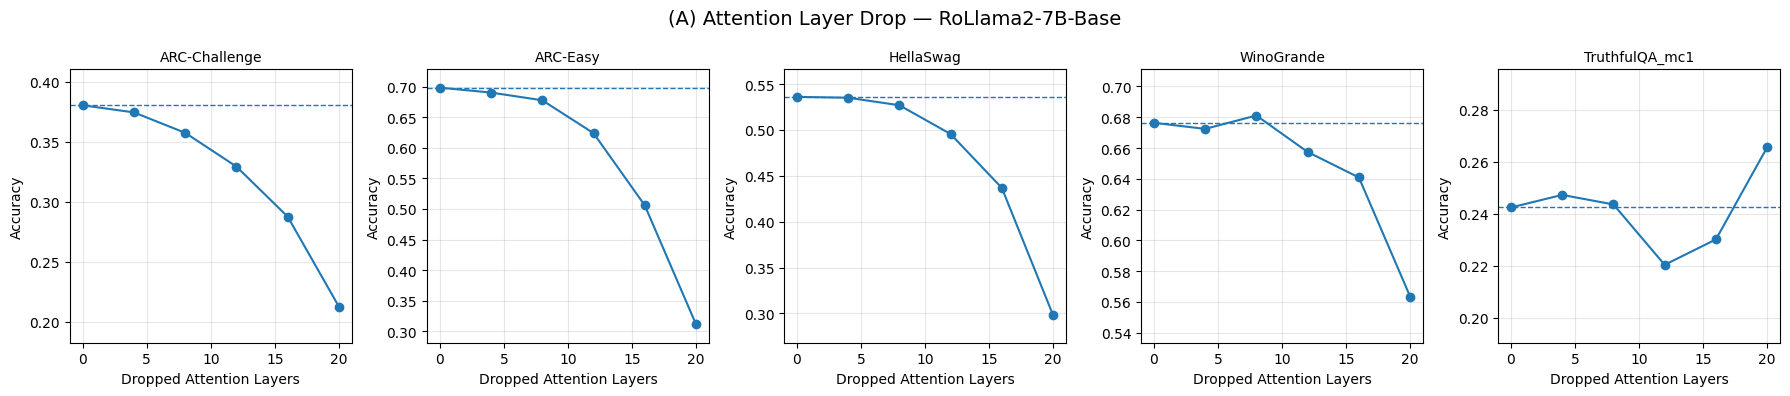

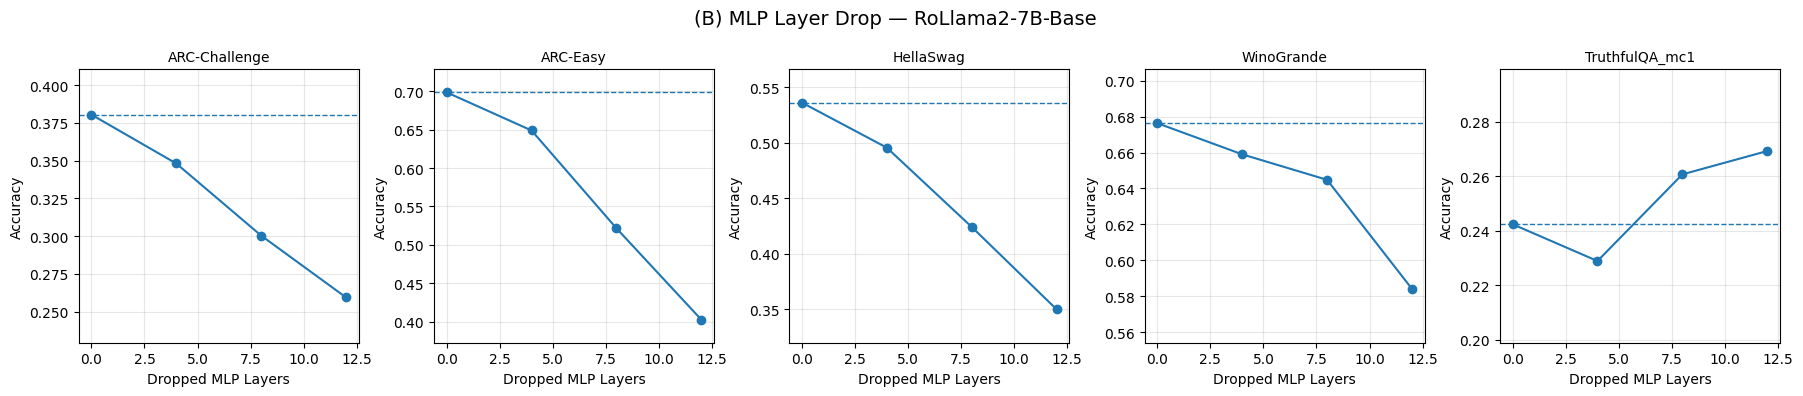

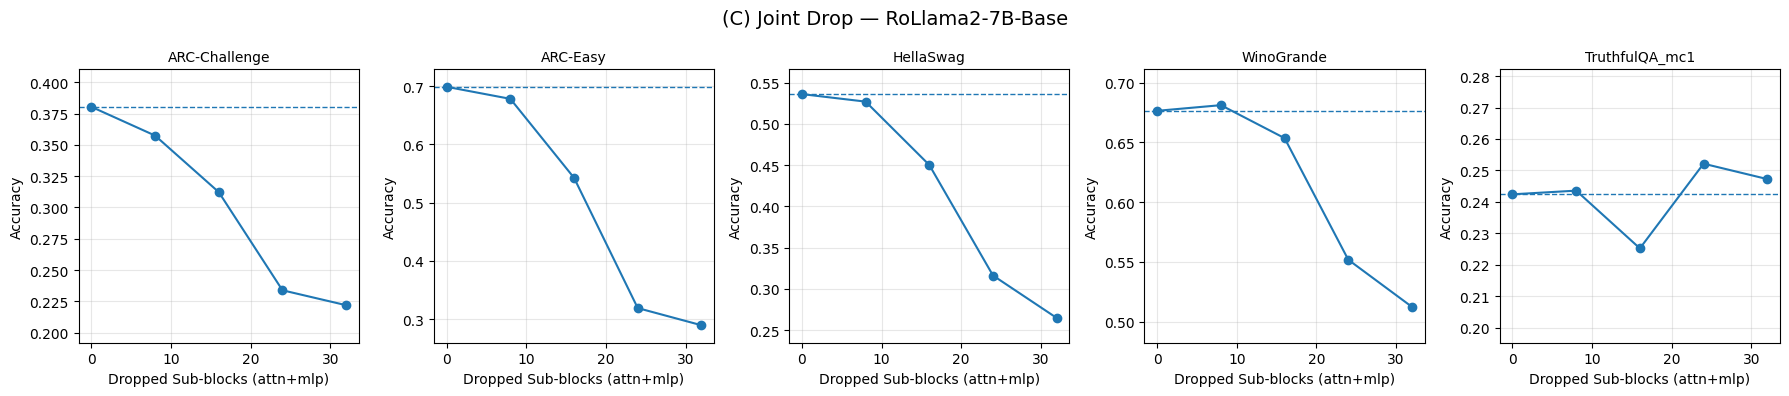

In [ ]:
import json
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

baseline = {
    "ARC-Challenge": 0.3805,
    "ARC-Easy": 0.6987,
    "HellaSwag": 0.5360,
    "WinoGrande": 0.6764,
    "TruthfulQA_mc1": 0.2424,
}

DIR_ATTN  = Path("./results_attn_drop")
DIR_MLP   = Path("./results_mlp_drop")
DIR_JOINT = Path("./results_joint_drop")

TASK_SPECS = {
    "arc_challenge":   ("ARC-Challenge", "acc,none"),
    "arc_easy":        ("ARC-Easy",      "acc,none"),
    "hellaswag":       ("HellaSwag",     "acc,none"),         
    "winogrande":      ("WinoGrande",    "acc,none"),
    "truthfulqa_mc1":  ("TruthfulQA_mc1","acc,none"),
}

DISPLAY_TASKS = [v[0] for v in TASK_SPECS.values()]  

DROP_RE = re.compile(r"drop_(\d+)")

def parse_drop_from_filename(p: Path) -> int:
    """
    Extracts the drop count from a filename like:
      rollama_attn_drop_4_2026-...json
      rollama_joint_drop_16_2026-...json
    """
    m = DROP_RE.search(p.name)
    if not m:
        raise ValueError(f"Could not parse drop count from filename: {p.name}")
    return int(m.group(1))

def load_scores_from_json(p: Path) -> dict:
    """
    Returns dict: {display_task_name: score_float}
    """
    obj = json.loads(p.read_text(encoding="utf-8"))
    res = obj.get("results", {})
    out = {}
    for task_key, (disp, metric_key) in TASK_SPECS.items():
        if task_key not in res:
            raise KeyError(f"Missing task '{task_key}' in {p}")
        if metric_key not in res[task_key]:
            raise KeyError(f"Missing metric '{metric_key}' for '{task_key}' in {p}")
        out[disp] = float(res[task_key][metric_key])
    return out

def read_experiment_dir(dir_path: Path) -> tuple[np.ndarray, dict]:
    """
    Reads all *.json files in dir_path, groups by drop count (in case multiple timestamps),
    and returns:
      x: sorted np.ndarray of drop counts (excluding baseline 0)
      y: dict {task_display: np.ndarray aligned with x}
    Policy if multiple JSONs for same drop: keep the newest (by filename sort).
    """
    files = sorted(dir_path.glob("*.json"))
    if not files:
        raise FileNotFoundError(f"No JSON files found in: {dir_path.resolve()}")

    # pick one file per drop count (newest by filename sort)
    by_drop = {}
    for f in files:
        d = parse_drop_from_filename(f)
        by_drop[d] = f  # overwrite => keep last in sorted order

    drops = np.array(sorted(by_drop.keys()), dtype=int)

    y = {disp: [] for disp in DISPLAY_TASKS}
    for d in drops:
        scores = load_scores_from_json(by_drop[d])
        for disp in DISPLAY_TASKS:
            y[disp].append(scores[disp])

    for disp in DISPLAY_TASKS:
        y[disp] = np.array(y[disp], dtype=float)

    return drops, y

def add_baseline_zero(x: np.ndarray, y: dict) -> tuple[np.ndarray, dict]:
    """
    Prepends x=0 and baseline scores to each task series.
    """
    x0 = np.concatenate([np.array([0], dtype=int), x])
    y0 = {}
    for disp in DISPLAY_TASKS:
        y0[disp] = np.concatenate([np.array([baseline[disp]], dtype=float), y[disp]])
    return x0, y0

def plot_panel(title: str, x: np.ndarray, y: dict, xlabel: str):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=False)
    fig.suptitle(title, fontsize=14)

    for ax, disp in zip(axes, DISPLAY_TASKS):
        ax.plot(x, y[disp], marker="o")
        ax.set_title(disp, fontsize=10)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Accuracy")
        ax.grid(True, alpha=0.3)

        # Baseline horizontal line
        ax.axhline(baseline[disp], linestyle="--", linewidth=1)

        ymin = min(float(y[disp].min()), baseline[disp]) - 0.03
        ymax = max(float(y[disp].max()), baseline[disp]) + 0.03
        ax.set_ylim(max(0.0, ymin), min(1.0, ymax))

    plt.tight_layout()
    plt.show()

attn_x_raw,  attn_y_raw  = read_experiment_dir(DIR_ATTN)
mlp_x_raw,   mlp_y_raw   = read_experiment_dir(DIR_MLP)
joint_x_raw, joint_y_raw = read_experiment_dir(DIR_JOINT)

attn_x,  attn_y  = add_baseline_zero(attn_x_raw,  attn_y_raw)
mlp_x,   mlp_y   = add_baseline_zero(mlp_x_raw,   mlp_y_raw)
joint_x, joint_y = add_baseline_zero(joint_x_raw, joint_y_raw)

plot_panel("(A) Attention Layer Drop — RoLlama2-7B-Base", attn_x, attn_y, "Dropped Attention Layers")
plot_panel("(B) MLP Layer Drop — RoLlama2-7B-Base", mlp_x, mlp_y, "Dropped MLP Layers")
plot_panel("(C) Joint Drop — RoLlama2-7B-Base", joint_x, joint_y, "Dropped Sub-blocks (attn+mlp)")
